<a href="https://colab.research.google.com/github/BoninCantCode/Computer-Vision-Project/blob/adding-directories/ComputerVisionProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<center><h1> <b> Object Detection Using YOLO <b> </h1></center>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Importing required Libraries

In [2]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
import cv2
import seaborn as sns
import glob
import xml.etree.ElementTree as ET
from PIL import Image
import os
import shutil

# Dataset Description






Fruit Images for Object Detection

available on kaggle => https://www.kaggle.com/datasets/mbkinaci/fruit-images-for-object-detection


- 240 images in train folder. 60 images in test folder.

- 3 different fruits:

    - Apple

    - Banana

    - Orange

The labels are in xml format, which is Extensible markup language.Storing image dataset labels in XML format is quite common. XML provides a clear, hierarchical structure which is ideal for representing the complex data associated with image labels. This includes not just the class of the object, but potentially a wealth of other information like bounding box coordinates, object IDs, and additional metadata.


# Data Preprocessing

For preprocessing:
- We have to convert the dataset into that acceptable by YOLO.
  - Heirarchy of folders should be the one accepted by YOLO
  - Labels format should be darknet YOLO.
  - Labels files should be .txt files
- Check and see if there are any missing labels or images. And remove them from dataset.


## Heirarchy of Folders correction

Defining paths to train and test folders.

In [3]:
test_dir = '/content/drive/MyDrive/IAT360 Project/YOLO Ready Images'
train_dir = '/content/drive/MyDrive/Roboflow/train'



The train and test folders have all the images and labels together.

But for YOLO, the directories should be in:

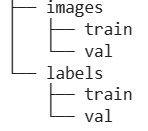


Making directories according to above struture of folders

In [5]:
#import os
#exist_ok=True means it won't error if you run it again

#os.makedirs('/content/drive/MyDrive/Roboflow/Final_data')
os.makedirs('/content/drive/MyDrive/Roboflow/Final_data/images', exist_ok=True)
os.makedirs('/content/drive/MyDrive/Roboflow/Final_data/labels', exist_ok=True)
os.makedirs('/content/drive/MyDrive/Roboflow/Final_data/images/train', exist_ok=True)
os.makedirs('/content/drive/MyDrive/Roboflow/Final_data/images/val', exist_ok=True)
os.makedirs('/content/drive/MyDrive/Roboflow/Final_data/labels/train', exist_ok=True)
os.makedirs('/content/drive/MyDrive/Roboflow/Final_data/labels/val', exist_ok=True)


In [6]:
#set the paths to labels and images directory
label_dir= "/content/drive/MyDrive/Roboflow/Final_data/labels"
image_dir="/content/drive/MyDrive/Roboflow/Final_data/images"

Copy XML files and jpg files from the train folder to the folders created.

In [7]:
#import shutil
#run it once for copying!

#Copy Roboflow train labels and images
for file in os.listdir(train_dir + "/labels"):
    if file.endswith(".txt"):
        shutil.copy(os.path.join(train_dir, "labels", file), os.path.join(label_dir, "train"))
for file in os.listdir(train_dir + "/images"):
    if file.lower().endswith((".jpg", ".jpeg", ".png")):
        image = Image.open(os.path.join(train_dir, "images", file))
        image = image.convert("RGB")
        new_filename = os.path.splitext(file)[0] + ".jpg"
        image.save(os.path.join(image_dir, "train", new_filename), "JPEG")


#Copy our own labels and images (inside each person's folder) to val
for root, dirs, files in os.walk(test_dir):
    for file in files:
        if file.endswith(".txt") and file != "labels.txt":
            shutil.copy(os.path.join(root, file), os.path.join(label_dir, "val"))
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
            image = Image.open(os.path.join(root, file))
            image = image.convert("RGB")
            new_filename = os.path.splitext(file)[0] + ".jpg"
            image.save(os.path.join(image_dir, "val", new_filename), "JPEG")

Visualizing somme pictures from the dataset

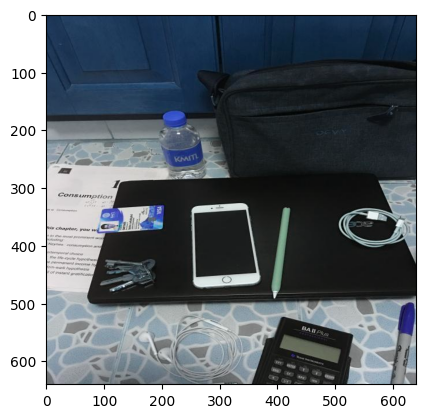

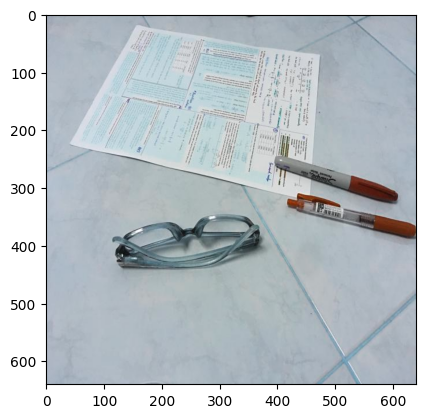

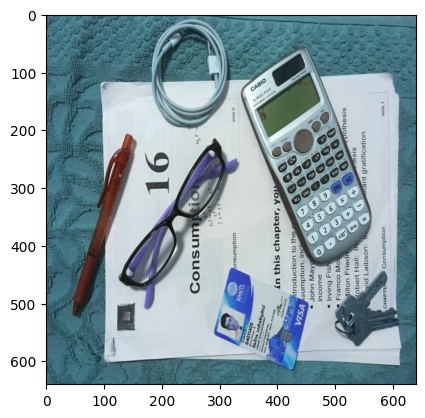

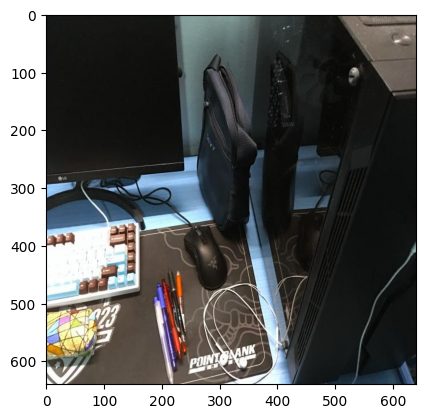

In [8]:
#visualize first four sample images from train data
for idx, image in enumerate(os.listdir(os.path.join(image_dir, "train"))):
    img = cv2.imread(os.path.join(image_dir,"train", image), 1)
    plt.imshow(img)
    plt.show()

    if idx == 3:
        break

## Creating Text files for labels
Creating Dataframes from .xml files, from which we will eventually create .txt file for each image


In [17]:
#import glob
import yaml

#class names from Roboflow (line order = class id)
with open('/content/drive/MyDrive/Roboflow/data.yaml') as f:
    train_names = yaml.safe_load(f)['names']
if isinstance(train_names, dict):
    train_names = [train_names[k] for k in sorted(train_names)]
print("Roboflow classes:", train_names)

df = {'name': [],
      'label': [],
      'width': [],
      'height': [],
     'xmin': [],
     'ymin': [],
     'xmax': [],
     'ymax': []}

skipped = 0

#Our labels are YOLO .txt files: "class x_center y_center box_width box_height" (all 0-1)
for idx, anno in enumerate(glob.glob(label_dir+"/train" + '/*.txt')):

    name = anno.split('/')[-1][0:-4]
    img_path = os.path.join(image_dir, "train", name + ".jpg")
    if not os.path.exists(img_path):
        continue
    width, height = Image.open(img_path).size

    for line in open(anno):
        parts = line.split()
        if len(parts) != 5:
            skipped += 1
            continue
        c = int(float(parts[0]))
        xc, yc, bw, bh = [float(p) for p in parts[1:]]

        df['label'] += [train_names[c] if c < len(train_names) else None]
        df['width'] += [width]
        df['height'] += [height]
        df['name'] += [name]
        df['xmin'] += [int(round((xc - bw/2) * width))]
        df['ymin'] += [int(round((yc - bh/2) * height))]
        df['xmax'] += [int(round((xc + bw/2) * width))]
        df['ymax'] += [int(round((yc + bh/2) * height))]

print("boxes read:", len(df['name']), "| lines skipped (not 5 values):", skipped)

Roboflow classes: ['Apple-Pencil', 'Bag', 'Calculator', 'Charging-cable', 'Earphones', 'Glasses', 'Keyboard', 'Keys', 'Laptop', 'Lecture-notes', 'Markers', 'Mobile phone', 'Mouse', 'PC', 'Pen', 'Screen', 'StudentID_card', 'Wallet', 'Watch', 'Water bottle', 'iPad-Air', 'iPad-Pro']
boxes read: 43 | lines skipped (not 5 values): 6965


Doing the same for validation data labels.


In [18]:
#class names from our own labels.txt (line order = class id)
with open(os.path.join(test_dir, "labels.txt")) as f:
    val_names = [l.strip() for l in f if l.strip()]
print("Our classes:", val_names)

df2 = {'name': [],
      'label': [],
      'width': [],
      'height': [],
     'xmin': [],
     'ymin': [],
     'xmax': [],
     'ymax': []}

skipped = 0

for idx, anno in enumerate(glob.glob(label_dir+"/val" + '/*.txt')):

    name = anno.split('/')[-1][0:-4]
    img_path = os.path.join(image_dir, "val", name + ".jpg")
    if not os.path.exists(img_path):
        continue
    width, height = Image.open(img_path).size

    for line in open(anno):
        parts = line.split()
        if len(parts) != 5:
            skipped += 1
            continue
        c = int(float(parts[0]))
        xc, yc, bw, bh = [float(p) for p in parts[1:]]

        df2['label'] += [val_names[c] if c < len(val_names) else None]
        df2['width'] += [width]
        df2['height'] += [height]
        df2['name'] += [name]
        df2['xmin'] += [int(round((xc - bw/2) * width))]
        df2['ymin'] += [int(round((yc - bh/2) * height))]
        df2['xmax'] += [int(round((xc + bw/2) * width))]
        df2['ymax'] += [int(round((yc + bh/2) * height))]

print("boxes read:", len(df2['name']), "| lines skipped (not 5 values):", skipped)

Our classes: ['Apple-Pencil', 'Bag', 'Calculator', 'Charging-cable', 'Earphones', 'Glasses', 'Keyboard', 'Keys', 'Laptop', 'Lecture-notes', 'Markers', 'Mobile phone', 'Mouse', 'PC', 'Pen', 'Screen', 'StudentID_card', 'Wallet', 'Watch', 'Water bottle']
boxes read: 100 | lines skipped (not 5 values): 0


In [19]:
import pandas as pd
train_df = pd.DataFrame(df)
val_df=pd.DataFrame(df2)
#df1.head()
val_df.head()

,name,label,width,height,xmin,ymin,xmax,ymax
0,tejas_lunchbox5,Earphones,4000,2252,195,658,1823,1406
1,tejas_lunchbox5,Earphones,4000,2252,1719,469,3430,1726
2,tejas_mouse1,Earphones,4000,2252,787,322,3527,1854
3,tejas_mouse2,Earphones,4000,2252,361,459,3323,1884
4,tejas_mouse3,Earphones,4000,2252,758,159,4000,1797


In [20]:
train_df.head(5)

,name,label,width,height,xmin,ymin,xmax,ymax
0,IMG_2027_JPG.rf.fa01be48c9b42a7e9721f1f737ec63c2,iPad-Air,640,640,274,130,640,563
1,IMG_1391_JPG.rf.e175dd0b7b17aa6678b4837a1c081ac2,Keys,640,640,263,181,321,233
2,IMG_1634_JPG.rf.856069fed1f8ddcbd1ec45c7f6155528,Pen,640,640,382,23,448,255
3,IMG_1322_JPG.rf.50819a00984e20921bbd8c6f528bcba1,Mobile phone,640,640,88,45,184,220
4,IMG_1322_JPG.rf.50819a00984e20921bbd8c6f528bcba1,Glasses,640,640,192,128,316,218


Visualizing one of the image in train set with the bounding box

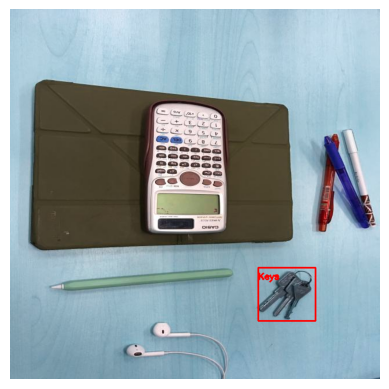

In [21]:
index= 10 #picture to visualize

#import cv2
image = cv2.imread(os.path.join(image_dir,"train", train_df["name"][index]+".jpg"), 1)
# Draw rectangle
cv2.rectangle(image, (train_df['xmin'][index], train_df['ymin'][index]), (train_df['xmax'][index], train_df['ymax'][index]), (255, 0, 0), 2)
# Put label (class_id) near the bbox
label = train_df["label"][index]
cv2.putText(image, str(label), (train_df['xmin'][index], train_df['ymin'][index]+20), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255,0,0), 2)
# Display image
plt.imshow(image)
plt.axis('off')
plt.show()

Checking to see if the above image has bounding boxes around other apples or not.

In [22]:
train_df["name"][index]
filtered_df = train_df[train_df['name'] == train_df["name"][index]]
print(filtered_df)

                                                name         label  width  \
7   IMG_1452_JPG.rf.cc995487cd90ab5383898e7fa123193e    Calculator    640   
8   IMG_1452_JPG.rf.cc995487cd90ab5383898e7fa123193e      iPad-Air    640   
9   IMG_1452_JPG.rf.cc995487cd90ab5383898e7fa123193e  Apple-Pencil    640   
10  IMG_1452_JPG.rf.cc995487cd90ab5383898e7fa123193e          Keys    640   
11  IMG_1452_JPG.rf.cc995487cd90ab5383898e7fa123193e     Earphones    640   
12  IMG_1452_JPG.rf.cc995487cd90ab5383898e7fa123193e           Pen    640   

    height  xmin  ymin  xmax  ymax  
7      640   234   159   382   389  
8      640    31   118   497   421  
9      640    57   445   396   492  
10     640   429   447   528   539  
11     640   187   525   400   640  
12     640   530   204   640   394  


Checking to see the datatypes of all the columns and if there is any null value that needs to be eliminated from the data.

In [23]:
val_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   name    100 non-null    object
 1   label   100 non-null    object
 2   width   100 non-null    int64 
 3   height  100 non-null    int64 
 4   xmin    100 non-null    int64 
 5   ymin    100 non-null    int64 
 6   xmax    100 non-null    int64 
 7   ymax    100 non-null    int64 
dtypes: int64(6), object(2)
memory usage: 6.4+ KB


What different types of labels are assigned to each sample and checking if they match the provided label/class information, i.e. there are no extra labels due to mistakes in spellings etc.

In [ ]:
print(train_df['label'].unique())
print(val_df['label'].unique())

['apple' 'banana' 'orange']
['banana' 'apple' 'orange']


We need to map labels to class_ids required for YOLO

In [ ]:
label_map = { 'orange': 0,
            'apple': 1,
            'banana': 2}

train_df['class'] = train_df['label'].map(label_map)
val_df['class'] = val_df['label'].map(label_map)

In [ ]:
train_df.head()

,name,label,width,height,xmin,ymin,xmax,ymax,class
0,apple_12,apple,450,428,43,21,350,353,1
1,apple_15,apple,1400,1046,643,364,1396,1046,1
2,apple_1,apple,0,0,8,15,331,349,1
3,apple_13,apple,800,800,415,261,720,567,1
4,apple_13,apple,800,800,105,426,393,691,1


convertig the bounding box format to the one required by YOLO:




In [ ]:
# Training data
train_df['x_center'] = (train_df['xmin']+train_df['xmax'])/(2*train_df["width"])
train_df['y_center'] = (train_df['ymin']+train_df['ymax'])/(2*train_df["height"])
train_df['box_width'] = (train_df['xmax']-train_df['xmin'])/ train_df["width"]
train_df['box_height'] = (train_df['ymax']-train_df['ymin'])/train_df["height"]

#Validation data
val_df['x_center'] = (val_df['xmin']+val_df['xmax'])/(2*val_df["width"])
val_df['y_center'] = (val_df['ymin']+val_df['ymax'])/(2*val_df["height"])
val_df['box_width'] = (val_df['xmax']-val_df['xmin'])/ val_df["width"]
val_df['box_height'] = (val_df['ymax']-val_df['ymin'])/val_df["height"]

In [ ]:
train_df.head()

,name,label,width,height,xmin,ymin,xmax,ymax,class,x_center,y_center,box_width,box_height
0,apple_12,apple,450,428,43,21,350,353,1,0.436667,0.436916,0.682222,0.775701
1,apple_15,apple,1400,1046,643,364,1396,1046,1,0.728214,0.673996,0.537857,0.652008
2,apple_1,apple,0,0,8,15,331,349,1,inf,inf,inf,inf
3,apple_13,apple,800,800,415,261,720,567,1,0.709375,0.517500,0.381250,0.382500
4,apple_13,apple,800,800,105,426,393,691,1,0.311250,0.698125,0.360000,0.331250


Deleting all the sample with Nan values in training and validation data

In [ ]:
#training
print("before deleting (train data): " , train_df.shape)
train_df.replace([np.inf, -np.inf], np.nan, inplace=True)
train_df.dropna(inplace=True)
print("after deleting(train_data): " ,train_df.shape)

#validation
print("before deleting (val data): " , val_df.shape)
val_df.replace([np.inf, -np.inf], np.nan, inplace=True)
val_df.dropna(inplace=True)
print("after deleting(val data): " , val_df.shape)



before deleting (train data):  (465, 13)
after deleting(train_data):  (420, 13)
before deleting (val data):  (117, 13)
after deleting(val data):  (110, 13)


converting the dataframe to type *str* (string) to be stored in text files.

In [ ]:
train_df = train_df.astype(str)
val_df = val_df.astype(str)

If there are more than one bounding boxes in single image, they should be written in one text file. As, you can see in the below example that one image has so many bounding boxes.

In [ ]:
filtered_df = train_df[train_df['name'] == train_df["name"][3]]
(filtered_df.head(15))

,name,label,width,height,xmin,ymin,xmax,ymax,class,x_center,y_center,box_width,box_height
3,apple_13,apple,800,800,415,261,720,567,1,0.709375,0.5175,0.38125,0.3825
4,apple_13,apple,800,800,105,426,393,691,1,0.31125,0.698125,0.36,0.33125
5,apple_13,apple,800,800,194,290,477,545,1,0.419375,0.521875,0.35375,0.31875


In [14]:
#file_name = [x.split('.')[0] for x in df1["name"]]

#TRAINING DATA
#finding all the unique names:
unique_names= train_df['name'].unique()

#for each unique name, containing multiple bboxes, combine them together.
for name in unique_names:
  data = train_df[train_df.name == name]
  box_list = []
  for idx in range(len(data)):
        row = data.iloc[idx]
        box_list.append(row['class']+" "+row['x_center']+" "+row['y_center']+" "+ row['box_width']+" "+row['box_height'])

#writing on text files
  text = "\n".join(box_list)
  with open(f'{label_dir}/train/{name}.txt', 'w') as file:
            file.write(text)
#############################################################################################
#VALIDATION DATA
#finding all the unique names:
unique_names= val_df['name'].unique()

#for each unique name, containing multiple bboxes, combine them together.
for name in unique_names:
  data = val_df[val_df.name == name]
  box_list = []
  for idx in range(len(data)):
        row = data.iloc[idx]
        box_list.append(row['class']+" "+row['x_center']+" "+row['y_center']+" "+ row['box_width']+" "+row['box_height'])

#writing on text files
  text = "\n".join(box_list)
  with open(f'{label_dir}/val/{name}.txt', 'w') as file:
            file.write(text)

## Checking Missing Files

Checking the folders if every image file has a corresponding label file


(We will copy the code, we already used in previous turorial after updating)

In [ ]:
#The lists of all the images and labels for train and validation set:
train_images=glob.glob(os.path.join(image_dir, "train",'*.jpg'))
train_labels=glob.glob(os.path.join(label_dir, "train",'*.txt'))
val_images=glob.glob(os.path.join(image_dir, "val",'*.jpg'))
val_labels=glob.glob(os.path.join(label_dir, "val",'*.txt'))
#print(val_labels)

# Get the list of filenames without extensions
image_files_train = {file.split("/")[-1].split(".")[0] for file in train_images}
label_files_train = {file.split("/")[-1].split(".")[0] for file in train_labels}

image_files_val = {file.split("/")[-1].split(".")[0] for file in val_images}
label_files_val = {file.split("/")[-1].split(".")[0] for file in val_labels}
#print(image_files_val)



In [ ]:
print(len(image_files_val), "  =  ", len(label_files_val))

56   =   56


In [ ]:
print(len(image_files_train), "  =  ", len(label_files_train))

207   =   207


In [ ]:
# Find extra files in each folder

#TRAINING DATA
extra_images_train = image_files_train - label_files_train
extra_labels_train = label_files_train - image_files_train

# Output the results
print(f"Training Extra images (without corresponding labels): {extra_images_train}")
print(f"Training Extra labels (without corresponding images): {extra_labels_train}")


#VALIDATION DATA
extra_images_val = image_files_val - label_files_val
extra_labels_val = label_files_val - image_files_val

# Output the results
print(f"Validation Extra images (without corresponding labels): {extra_images_val}")
print(f"Validation Extra labels (without corresponding images): {extra_labels_val}")

Training Extra images (without corresponding labels): {'banana_71', 'apple_28', 'orange_42', 'orange_35', 'orange_51', 'orange_64', 'orange_30', 'orange_22', 'apple_8', 'banana_57', 'banana_72', 'banana_53', 'orange_11', 'banana_75', 'banana_60', 'orange_59', 'orange_50', 'orange_70', 'mixed_16', 'banana_35', 'orange_13', 'orange_18', 'orange_4', 'apple_43', 'apple_20', 'apple_42', 'apple_44', 'apple_1', 'banana_25', 'orange_1', 'apple_17', 'apple_37', 'orange_68'}
Training Extra labels (without corresponding images): set()
Validation Extra images (without corresponding labels): {'apple_79', 'banana_87', 'apple_92', 'orange_94'}
Validation Extra labels (without corresponding images): set()


Make sure that the above info is correct by chceking the data manually.

Now removing from the dataset:

In [ ]:
for file in extra_images_train:
     os.remove(os.path.join(image_dir, "train", file + '.jpg')) # or '.png' depending on your image format

for file in extra_images_val:
     os.remove(os.path.join(image_dir, "val", file + '.jpg'))

Now run the above cells again to find if all the missing data is deleted.

# Custom object detection using YOLO

First install and import

In [ ]:
%pip install ultralytics
import ultralytics
ultralytics.checks()

Ultralytics 8.4.76 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 47.2/112.6 GB disk)


In [ ]:
from ultralytics import YOLO

## Training YOLO

We are going to select small pretrained (on COCO dataset) model of YOLOv8

In [ ]:
model = YOLO('yolov8s.pt') # pretrained model

The detailed architecture of the model can be seen from:


In [ ]:
model

YOLO(
  (model): DetectionModel(
    (model): Sequential(
      (0): Conv(
        (conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (1): Conv(
        (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (2): C2f(
        (cv1): Conv(
          (conv): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
          (act): SiLU(inplace=True)
        )
        (cv2): Conv(
          (conv): Conv2d(96, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_s

In [ ]:
%%writefile config.yaml
path: /content/drive/MyDrive/Tutorials/Datasets/FRUIT DATA/Final_data
train: /content/drive/MyDrive/Tutorials/Datasets/FRUIT DATA/Final_data/images/train
#test: (test dataset folder path)
val: /content/drive/MyDrive/Tutorials/Datasets/FRUIT DATA/Final_data/images/val

# Classes
nc: 3 # replace based on your dataset's number of classes

# Class names
# replace all class names with your own classes' names
names:
  0: orange
  1: apple
  2: banana

Overwriting config.yaml


Please look at [Yolo train Docs](https://docs.ultralytics.com/modes/train/#train-settings) for hyperparameters for model tuning and configuration, e.g. lr0, imgsz, model etc.

In [ ]:
model.train(data="config.yaml",epochs=5,patience=5,batch=8, lr0=0.0005,imgsz=640,project="/content/drive/MyDrive/custom_folder")

Ultralytics 8.4.76 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=config.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=5, perspective=0.0, pl

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x781904201cd0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04

## Evaluation Metrics

[This](https://docs.ultralytics.com/guides/yolo-performance-metrics/) is a very good detailed explanation of different perfromance metrics in YOLO.

**Choosing the Right Metrics**

Choosing the right metrics to evaluate often depends on the specific application.

- mAP: Suitable for a broad assessment of model performance.

- IoU: Essential when precise object location is crucial.

- Precision: Important when minimizing false detections is a priority.

- Recall: Vital when it's important to detect every instance of an object.

- F1 Score: Useful when a balance between precision and recall is needed.


In [ ]:
metrics = model.val(project="/content/drive/MyDrive/custom_folder")  # no other arguments needed, dataset and settings remembered
metrics.box.map    # map50-95
metrics.box.map50  # map50
metrics.box.map75  # map75
metrics.box.maps   # a list contains map50-95 of each category
metrics.box.mp    # P
metrics.box.mr    # R

Ultralytics 8.4.76 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 11,126,745 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.7±0.3 ms, read: 27.6±22.4 MB/s, size: 49.7 KB)
val: Scanning /content/drive/MyDrive/Tutorials/Datasets/FRUIT DATA/Final_data/labels/val.cache... 56 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 56/56 19.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.5it/s 2.7s
                   all         56        110      0.689      0.766      0.776      0.552
                orange         21         41      0.743      0.927      0.925      0.688
                 apple         22         33      0.717      0.788      0.805      0.639
                banana         21         36      0.607      0.583      0.598       0.33
Speed: 10.2ms preprocess, 9.4ms inference, 0.0ms loss, 3.2ms postprocess per image
Results saved to

np.float64(0.7660137965016015)

Showing confusion matrix, that is already stored in detect/train folder

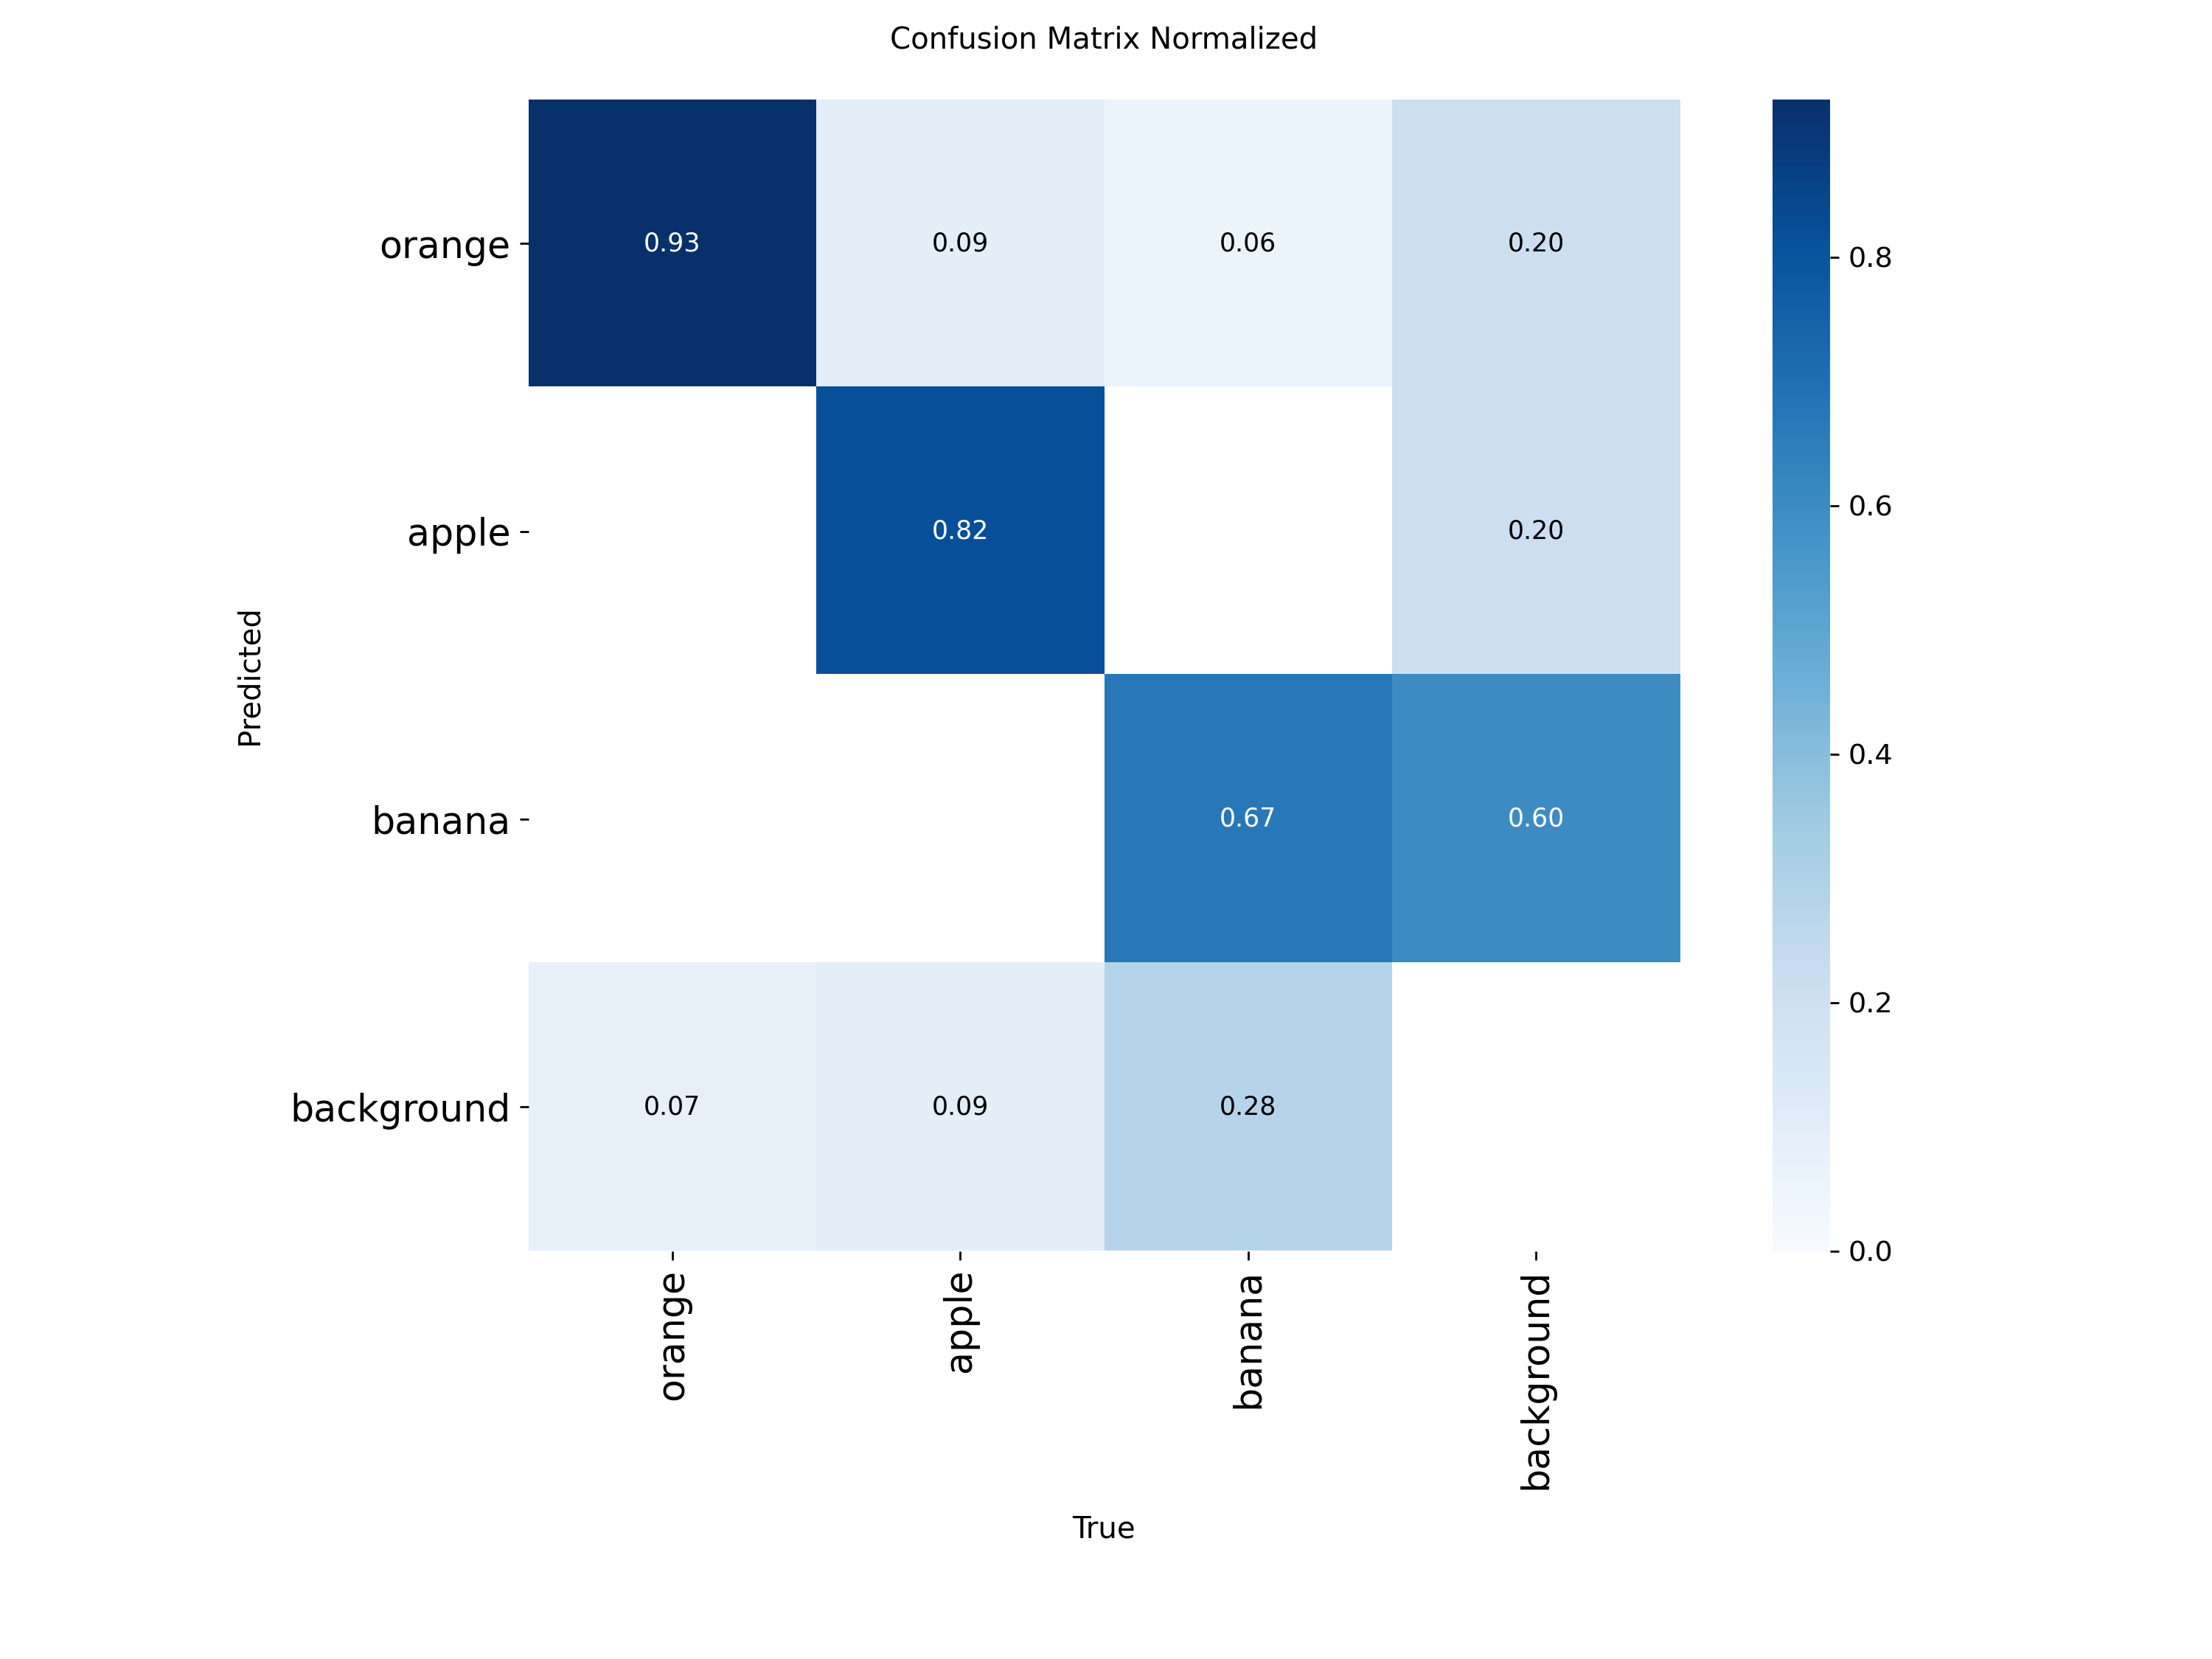

In [ ]:
%matplotlib inline
from PIL import Image

Image.open('/content/drive/MyDrive/custom_folder/train/confusion_matrix_normalized.png')

##Prediction

In [ ]:
model = YOLO("/content/drive/MyDrive/custom_folder/my_experiment/weights/best.pt")  # load a custom model

# Predict with the model with any image from internet?
results = model('https://www.freshpoint.com/wp-content/uploads/2019/08/freshpoint-produce-101-apples-bananas.jpg', save=True, project="/content/drive/MyDrive/custom_folder")


Found https://www.freshpoint.com/wp-content/uploads/2019/08/freshpoint-produce-101-apples-bananas.jpg locally at freshpoint-produce-101-apples-bananas.jpg
image 1/1 /content/freshpoint-produce-101-apples-bananas.jpg: 576x640 2 apples, 3 bananas, 16.4ms
Speed: 2.3ms preprocess, 16.4ms inference, 1.7ms postprocess per image at shape (1, 3, 576, 640)
Results saved to /content/drive/MyDrive/custom_folder/predict-2


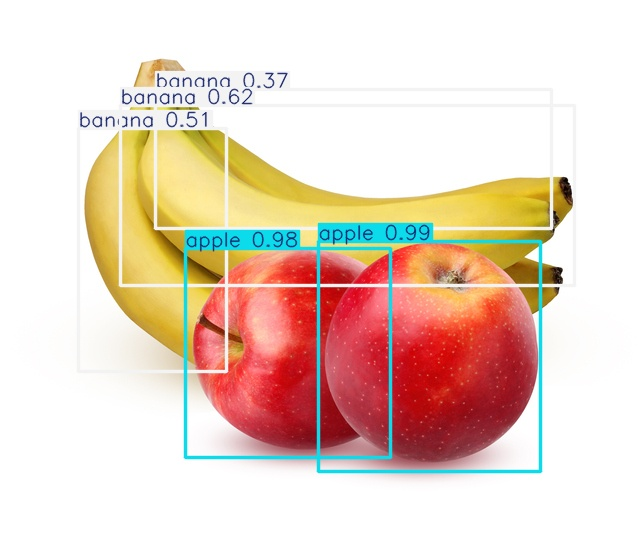

In [ ]:
# SHOW THE IMAGE STORED
%matplotlib inline
from PIL import Image

Image.open('/content/drive/MyDrive/custom_folder/predict-2/freshpoint-produce-101-apples-bananas.jpg')